# Introducción a los sensores remotos

Los sensores remotos, o teledetección, son el conjunto de técnicas que permiten obtener información de un objeto sin estar en contacto físico con él, midiendo la energía electromagnética que el objeto refleja o emite. El ojo humano es en sí mismo un sensor remoto, y una fotografía tomada desde un avión o una imagen captada por un satélite son extensiones de esa misma idea: registrar, a distancia, la radiación que llega desde la superficie terrestre y convertirla en datos que se pueden interpretar {cite}`chuvieco2008,lillesand2015`.

Todo sistema de teledetección tiene los mismos componentes. Hay una fuente de energía, que puede ser el Sol (sensores pasivos) o el propio sensor (sensores activos, como el radar o el LiDAR). Esa energía atraviesa la atmósfera, interactúa con la superficie y una parte regresa hacia el sensor, que la registra a bordo de una plataforma (un avión, un dron o un satélite). Los datos se transmiten a una estación en tierra, se procesan y finalmente un intérprete, humano o algorítmico, los convierte en información útil: un mapa geológico, un inventario de movimientos en masa o una medida de la deformación del terreno {cite}`ccrs`.

Para un geólogo, el valor de los sensores remotos está en la visión de conjunto. Las estructuras regionales, los contactos litológicos, los patrones de drenaje o las cicatrices de deslizamientos se reconocen mejor desde arriba que caminando sobre ellos, y una imagen permite cubrir en horas áreas que en campo tomarían meses. La fotointerpretación no reemplaza el trabajo de campo, lo orienta: indica dónde mirar y qué verificar.

## Breve historia

La teledetección nació con la fotografía. En 1858 Gaspard-Félix Tournachon, conocido como Nadar, tomó desde un globo sobre París la primera fotografía aérea de la que se tiene registro. A finales del siglo XIX se usaron cometas y hasta palomas con cámaras; una de las imágenes más célebres de esa época es la panorámica de San Francisco en ruinas que George R. Lawrence tomó con una cámara suspendida de cometas en 1906, semanas después del terremoto.

Las dos guerras mundiales impulsaron la fotografía aérea como herramienta de reconocimiento, y con ella se desarrollaron las cámaras métricas, la fotogrametría y los métodos de fotointerpretación que luego se aplicaron a la geología, la cartografía y los recursos naturales {cite}`ray1960`. En la segunda mitad del siglo XX la carrera espacial trasladó los sensores a órbita: en 1960 se lanzó TIROS-1, el primer satélite meteorológico, y en 1972 el Landsat 1 (ERTS-1) inauguró la observación sistemática de los recursos terrestres con un sensor multiespectral. Desde entonces se sumaron los sensores de radar de apertura sintética, como ERS-1 en 1991, los satélites comerciales de muy alta resolución, como IKONOS en 1999, y en la última década las constelaciones Sentinel del programa Copernicus y los nanosatélites que observan toda la Tierra a diario.

El cambio más reciente no es tanto de sensores como de acceso. Los archivos de Landsat y Sentinel son gratuitos, y plataformas como Google Earth Engine u openEO permiten procesar décadas de imágenes en la nube sin descargarlas. Eso convierte a la teledetección en una herramienta cotidiana de cualquier geocientífico, y es el enfoque de la última parte de este libro.

La celda siguiente dibuja una línea de tiempo con algunos de esos hitos.

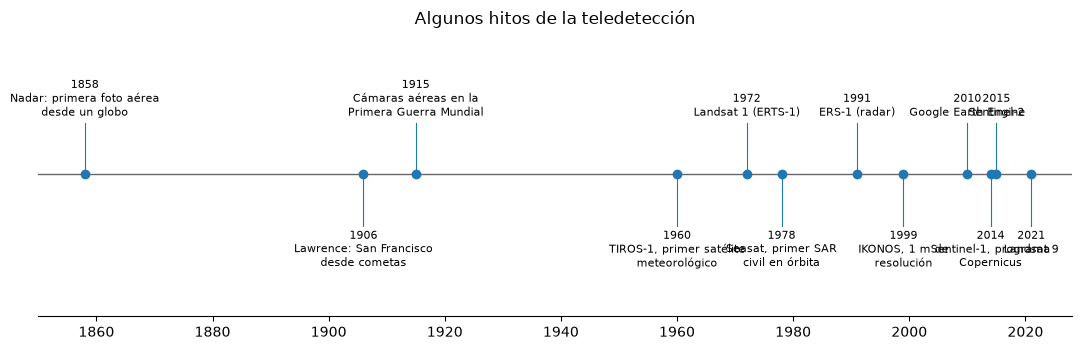

In [1]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100

hitos = [
    (1858, 'Nadar: primera foto aérea\ndesde un globo'),
    (1906, 'Lawrence: San Francisco\ndesde cometas'),
    (1915, 'Cámaras aéreas en la\nPrimera Guerra Mundial'),
    (1960, 'TIROS-1, primer satélite\nmeteorológico'),
    (1972, 'Landsat 1 (ERTS-1)'),
    (1978, 'Seasat, primer SAR\ncivil en órbita'),
    (1991, 'ERS-1 (radar)'),
    (1999, 'IKONOS, 1 m de\nresolución'),
    (2010, 'Google Earth Engine'),
    (2014, 'Sentinel-1, programa\nCopernicus'),
    (2015, 'Sentinel-2'),
    (2021, 'Landsat 9'),
]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.axhline(0, color='0.4', lw=1)
for i, (a, t) in enumerate(hitos):
    y = 1 if i % 2 == 0 else -1
    ax.plot([a, a], [0, 0.8 * y], color='tab:blue', lw=0.8)
    ax.plot(a, 0, 'o', color='tab:blue')
    ax.text(a, 0.85 * y, f'{a}\n{t}', ha='center', va='bottom' if y > 0 else 'top', fontsize=8)
ax.set_ylim(-2.2, 2.2)
ax.set_xlim(1850, 2028)
ax.set_yticks([])
for s in ['left', 'right', 'top']:
    ax.spines[s].set_visible(False)
ax.set_title('Algunos hitos de la teledetección')
plt.tight_layout()
plt.show()

## El proceso de teledetección como una cadena

Es útil pensar el proceso como una cadena en la que cada eslabón modifica la señal. La energía que sale del Sol se atenúa y se dispersa en la atmósfera, la superficie absorbe una parte y refleja otra según su composición, la radiación reflejada vuelve a cruzar la atmósfera y el sensor la registra con una resolución limitada en el espacio, en el espectro, en la radiometría y en el tiempo. Cada uno de esos pasos se estudia en un capítulo de la primera parte del libro, y las correcciones del capítulo {doc}`10_Preprocesamiento` buscan, precisamente, deshacer sus efectos para recuperar la propiedad que interesa, la reflectancia de la superficie.

La celda siguiente hace un cálculo muy simple de esa cadena para la banda roja: cuánta energía solar llega al sensor después de dos pasos por la atmósfera y de reflejarse en una superficie con una reflectancia dada. Las cifras son ilustrativas, pero muestran por qué el sensor recibe solo una pequeña fracción de la energía solar y por qué una atmósfera turbia puede borrar el contraste entre dos superficies.

In [2]:
import numpy as np

E_sol = 1550.0         # irradiancia solar exoatmosférica en el rojo, W m-2 um-1 (aprox.)
theta_s = np.radians(35)  # ángulo cenital solar
for nombre, T_atm in [('atmósfera limpia', 0.85), ('atmósfera turbia', 0.55)]:
    print(nombre)
    for sup, rho in [('agua', 0.03), ('vegetación', 0.05), ('suelo desnudo', 0.25)]:
        E_sup = E_sol * np.cos(theta_s) * T_atm      # irradiancia en la superficie
        L_sup = rho * E_sup / np.pi                  # radiancia reflejada (superficie lambertiana)
        L_sensor = L_sup * T_atm                     # radiancia que llega al sensor
        print(f'   {sup:14s} reflectancia {rho:4.2f} -> radiancia en el sensor {L_sensor:6.1f} W m-2 sr-1 um-1')

atmósfera limpia
   agua           reflectancia 0.03 -> radiancia en el sensor    8.8 W m-2 sr-1 um-1
   vegetación     reflectancia 0.05 -> radiancia en el sensor   14.6 W m-2 sr-1 um-1
   suelo desnudo  reflectancia 0.25 -> radiancia en el sensor   73.0 W m-2 sr-1 um-1
atmósfera turbia
   agua           reflectancia 0.03 -> radiancia en el sensor    3.7 W m-2 sr-1 um-1
   vegetación     reflectancia 0.05 -> radiancia en el sensor    6.1 W m-2 sr-1 um-1
   suelo desnudo  reflectancia 0.25 -> radiancia en el sensor   30.6 W m-2 sr-1 um-1


## Para profundizar

Los capítulos introductorios de {cite}`chuvieco2008` y de {cite}`lillesand2015` describen con detalle los componentes de un sistema de teledetección, y el tutorial del Centro Canadiense de Sensores Remotos {cite}`ccrs` es una introducción gratuita y muy gráfica. Para la historia de la fotografía aérea aplicada a la geología, el informe de {cite:t}`ray1960` sigue siendo una referencia.